# GIK2KM Data Science & Machine Learning

Dalarna University, VT25

© Joonas Pääkkönen

## Lab 3: Machine Learning (released May 5th, 2025)

## Deadline: Monday May 12th, 2025, 23:59 CET time

It is okay to work in pairs. However, if you work with another student, add his or her name below, too.

Upload your .ipynb file to Canvas. Use file name format “lab3 firstname lastname studentid.ipynb",
e.g., “lab3 jim jonsson v21abcde hanna jansson v21abcda.ipynb”. For this lab no video is to be recorded.

For grade G, execute all the given tasks.

Use Scikit-learn first and foremost, with the help of Pandas, NumPy, SciPy, Matplotlib and Seaborn, if needed.
Remember that Pandas dataframes come in very handy in data science.

Note: pairplots may take several seconds or even minutes to plot depending on how fast your system is.

Plagiarism: Do not blindly copy-paste anything. You need to be able to explain your solution in your own words and analyze the results. The plagiarism rules of the university apply. As explained above, you may work in pairs but in that case, add both names and email addresses below.

Make sure that your code runs before submitting.

Include all the outputs in the submission. This includes e.g. all pairplots, other figures, numerical values, etc.

Use Markdown cells for text explanations, and code cells for Python/Sklearn code.

Do not modify the title or this header information other than adding your name(s) and email(s) below:

### Student name(s): Ali Adrian Nasrat, Anna Backolars

### DU email address(es): alian@du.se, anba@du.se

## Task 1: k-means clustering

Task 1.1: Download the dry+bean+dataset.zip file from
https://archive.ics.uci.edu/ml/datasets/Dry+Bean+Dataset and save Dry_Bean_Dataset.xlsx to variable beandata.

In [4]:
import pandas as pd
import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns
import seaborn.objects as so

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [5]:
beandata = pd.read_excel(r'data/DryBeanDataset/Dry_Bean_Dataset.xlsx')
print(beandata)

        Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0      28395    610.291       208.178117       173.888747      1.197191   
1      28734    638.018       200.524796       182.734419      1.097356   
2      29380    624.110       212.826130       175.931143      1.209713   
3      30008    645.884       210.557999       182.516516      1.153638   
4      30140    620.134       201.847882       190.279279      1.060798   
...      ...        ...              ...              ...           ...   
13606  42097    759.696       288.721612       185.944705      1.552728   
13607  42101    757.499       281.576392       190.713136      1.476439   
13608  42139    759.321       281.539928       191.187979      1.472582   
13609  42147    763.779       283.382636       190.275731      1.489326   
13610  42159    772.237       295.142741       182.204716      1.619841   

       Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0          0.54981

Task 1.2: Plot the pairplot of beandata with hue set to "Class".

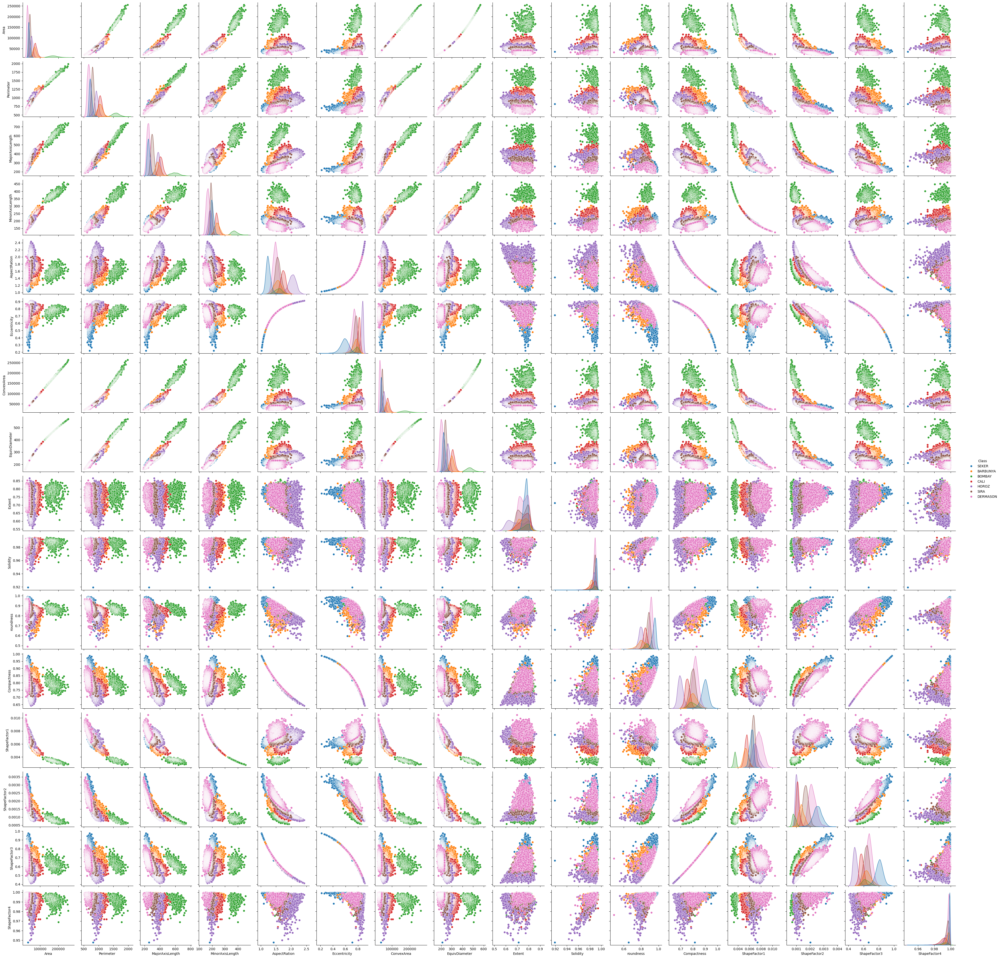

In [7]:
sns.pairplot(beandata, hue="Class")
plt.show()

Task 1.3: As it is explained on the "Dry Bean" website (see the link in Task 1.1), here the "Class" variable can be regarded as a categorical variable and the target variable in classification, and the other 16 variables can simply be called features. How many different classes are there for the target variable, and what are those classes? In other words, how many different beans are there, and what are their names?

### Seven different types of dry beans were used in this research, taking into account the features such as form, shape, type, and structure. Seven different registered varieties of dry beans with similar features in order to obtain uniform seed classification.

In [10]:
classes = beandata['Class'].unique()
num_classes = len(classes)

print(f"Number of classes: {num_classes}")
print("Classes (bean types):", classes)

Number of classes: 7
Classes (bean types): ['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


Task 1.4: Create a OneHotEncoder (from sklearn.preprocessing) and use it convert the classes into binary vectors.

In [12]:
encoder = OneHotEncoder(sparse_output=False)
onehot_classes = encoder.fit_transform(beandata[['Class']])

class_names = encoder.categories_[0]
onehot_df = pd.DataFrame(onehot_classes, columns=class_names)
onehot_df.head()

,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Task 1.5: What is the binary vector into which Sira beans were encoded?

In [14]:
# Find the position/index of 'SIRA' in the encoded vector
sira_index = list(class_names).index("SIRA")
print("Index of 'SIRA' in the one-hot vector:", sira_index)

# Create an empty vector and set 1 at the SIRA position
binary_vector = [0] * len(class_names)
binary_vector[sira_index] = 1

print("Binary vector for 'SIRA':", binary_vector)

Index of 'SIRA' in the one-hot vector: 6
Binary vector for 'SIRA': [0, 0, 0, 0, 0, 0, 1]


Task 1.6: Plot a scatterplot with Compactness on the x-axis and Minor Axis Length on the y-axis. Here all the datapoints should have the same color.

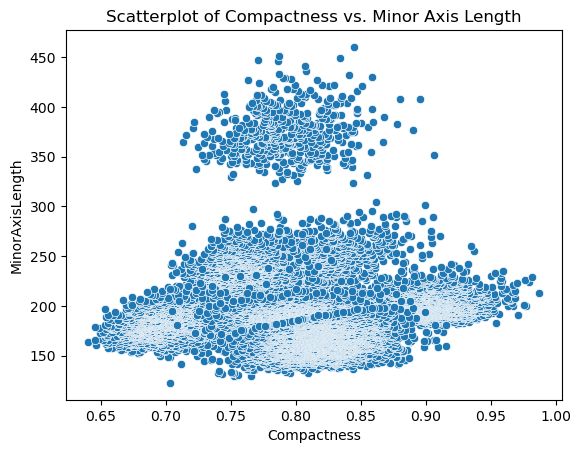

In [16]:
sns.scatterplot(data=beandata, x="Compactness", y="MinorAxisLength")
plt.title("Scatterplot of Compactness vs. Minor Axis Length")
plt.show()

### This plot shows the relationship between two features of beans:
	•	X-axis: Compactness — a measure of how compact or circular the bean is.
	•	Y-axis: MinorAxisLength — the length of the shorter axis of the bean’s fitted ellipse.

### Each point represents one bean.

Task 1.7: Use the Sklearn k-means algorithm to cluster the data into $k=2$ clusters, and plot a scatterplot that shows the clusters in different colors.

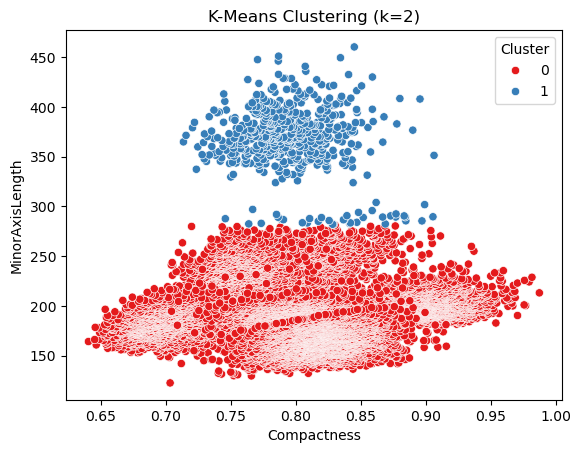

In [19]:
# Select two numerical features to cluster on (e.g., Compactness and MinorAxisLength)
def cluster(n = 2): 
    X = beandata[['Compactness', 'MinorAxisLength']]
    
    # Fit KMeans with 2 clusters
    kmeans = KMeans(n_clusters=n, random_state=0, n_init='auto')
    labels = kmeans.fit_predict(X)
    beandata['Cluster'] = labels 
    
    # Plot the clustered data
    sns.scatterplot(data=beandata, x='Compactness', y='MinorAxisLength', hue='Cluster', palette='Set1')
    plt.title(f"K-Means Clustering (k={n})")
    plt.show()

cluster()

Task 1.8: Explain in your own words what the silhouette score is. This information can be found on the Sklearn website.

### The silhouette score shows how well the K-Means algorithm grouped the points.
	•	If the score is high, it means the points are close to others in the same group and far from other groups → good clustering.
	•	If the score is low, it means the groups are not clear or mixed up.
	•	The score goes from -1 to 1:
	•	1 = perfect
	•	0 = unclear
	•	-1 = bad (wrong group)

### We use this score when we don’t know the true labels.

Task 1.9: Use Sklearn to find and print the silhouette score of the clustering of Task 1.7.

In [23]:
def sil_score(n = 2):
    X = beandata[['Compactness', 'MinorAxisLength']]
    kmeans = KMeans(n_clusters=n, random_state=0, n_init='auto')
    labels = kmeans.fit_predict(X)
    score_k2 = silhouette_score(X, beandata['Cluster'])
    print(f"Silhouette Score for k={n}: {score_k2:}")

sil_score()

Silhouette Score for k=2: 0.7986613734633661


Task 1.10: Use the Sklearn k-means algorithm to cluster the data into $k=3$ clusters, and plot a scatterplot that shows the three clusters in different colors.

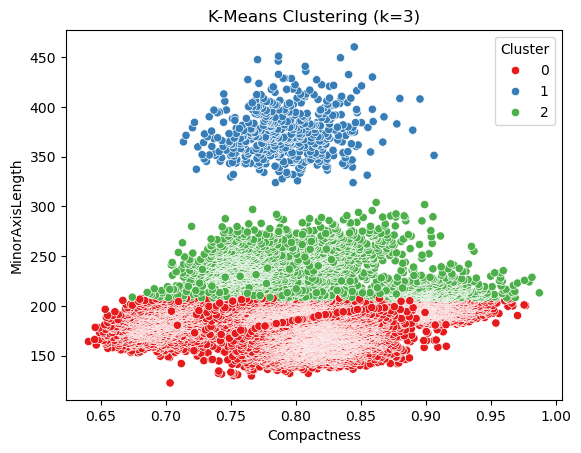

In [25]:
cluster(3)

Task 1.11: Use Sklearn to find and print the silhouette score of the clustering of Task 1.10.

In [27]:
sil_score(3)

Silhouette Score for k=3: 0.6277129803172946


Task 1.12: Which number of clusters, with $k=2$ or $k=3$, gave the better performance in terms of the silhouette score? Are the results in line with what you see in the figures? Which number of clusters seems more suitable when you look at the scatterplots? Explain in your own words below.

### The k=2 clustering has a higher silhouette score, meaning the beans were grouped more clearly and cleanly into two clusters than into three.

### The k=3 clustering might still make sense visually, but it’s less well-defined, with some points not fitting as clearly into their groups.

## Task 2: Comparing clustering algorithms

Task 2.1: Download buddymove+data+set.zip from https://archive.ics.uci.edu/ml/datasets/BuddyMove+Data+Set and save the buddymove_holidayiq.csv dataset to a variable called buddydata.

In [32]:
buddydata = pd.read_csv(r'data/buddymove_holidayiq.csv')
print(buddydata)

      User Id  Sports  Religious  Nature  Theatre  Shopping  Picnic
0      User 1       2         77      79       69        68      95
1      User 2       2         62      76       76        69      68
2      User 3       2         50      97       87        50      75
3      User 4       2         68      77       95        76      61
4      User 5       2         98      54       59        95      86
..        ...     ...        ...     ...      ...       ...     ...
244  User 245      18        139     148      129       129     168
245  User 246      22        114     228      104        84     168
246  User 247      20        124     178      104       158     174
247  User 248      20        133     149      139       144     213
248  User 249      20        143     149      139       159     143

[249 rows x 7 columns]


Task 2.2: Use Seaborn to plot the pairplot of buddydata with only one color for each datapoint.

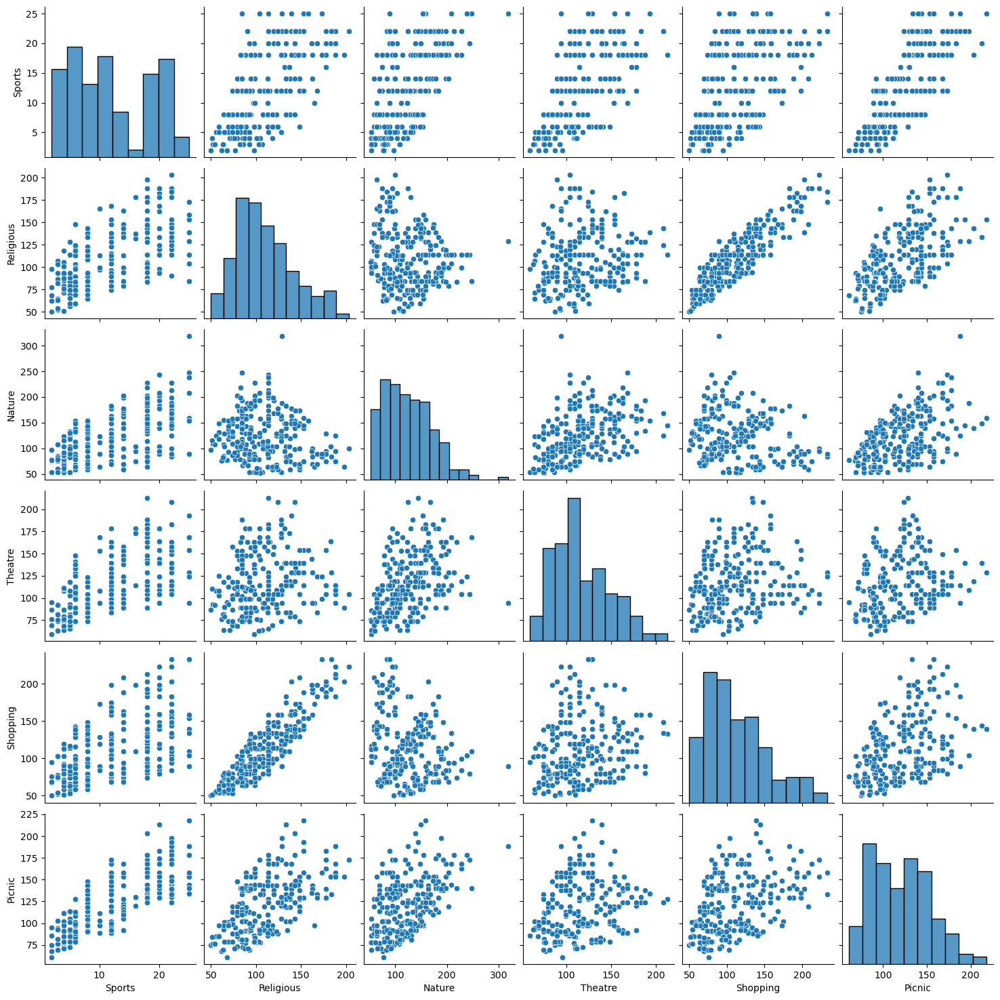

In [34]:
sns.pairplot(buddydata, vars=["Sports","Religious","Nature","Theatre","Shopping", "Picnic"])
plt.show()

Task 2.3: By looking at the pairplot, one might argue that based on features Nature and Shopping, the users could be grouped into 3 separate clusters. Plot only this scatterplot, with Nature on the x-axis and Shopping on the y-axis.

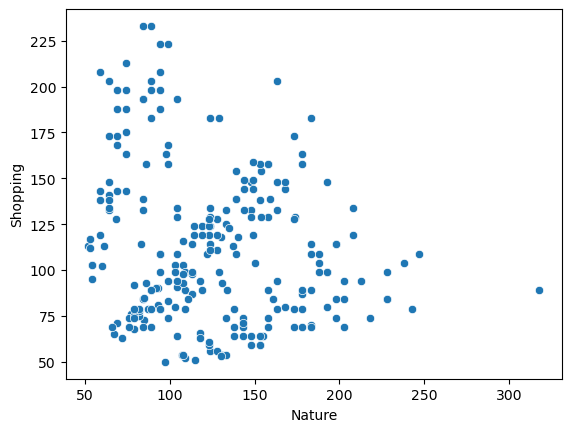

In [36]:
sns.scatterplot(data=buddydata, x="Nature", y="Shopping")
plt.show()

Task 2.4: Assuming that we have 3 different user groups, how would you describe each of these groups by looking at the scatterplot? Explain in your own words below based on how many reviews the users of each user group have made. See the website referred to in Task 2.1 for explanations of the features. 

#### Group 1 – Low Reviewers
- Few reviews in both Nature and Shopping.
- Found in the bottom-left corner.
- Not very active.

---

#### Group 2 – Medium Reviewers
- Some reviews in both categories.
- Found in the middle area.
- Moderately active.

---

#### Group 3 – High Reviewers
- Many reviews in both Nature and Shopping.
- Found in the top-right corner.
- Very active users.

---

#### Summary


\begin{array}{|c|c|c|c|}
\hline
\textbf{Group} & \textbf{Nature} & \textbf{Shopping} & \textbf{Activity Level} \\
\hline
1 & Low & Low & Low \\
2 & Medium & Medium & Medium \\
3 & High & High & High \\
\hline
\end{array}

Task 2.5: Use Sklearn to build a k-means clustering model (for the 2-dimensional dataset of Task 2.3) with $k=3$, plot the corresponding scatterplot so that datapoints belonging to different clusters have different colors, and finally also print the corresponding silhouette score.

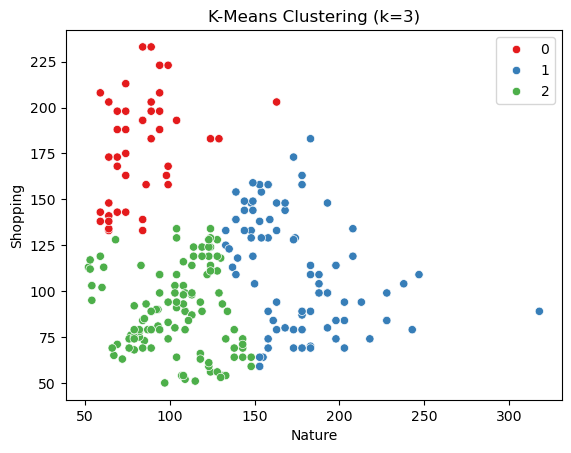

Silhouette Score for k=3: 0.42076886359021376


In [40]:
def cluster_and_score(n=3):
    X = buddydata[['Nature', 'Shopping']]
    
    kmeans = KMeans(n_clusters=n, random_state=0, n_init='auto')
    labels = kmeans.fit_predict(X)
    
    # Plot clusters
    sns.scatterplot(x=X['Nature'], y=X['Shopping'], hue=labels, palette='Set1')
    plt.title(f'K-Means Clustering (k={n})')
    plt.xlabel("Nature")
    plt.ylabel("Shopping")
    plt.show()
    
    score = silhouette_score(X, labels)
    print(f"Silhouette Score for k={n}: {score:}")
cluster_and_score()

Task 2.6: Use Sklearn to build a Gaussian mixture clustering model with 3 mixture components, plot the corresponding scatterplot so that datapoints belonging to different clusters have different colors, and finally also print the corresponding silhouette score.

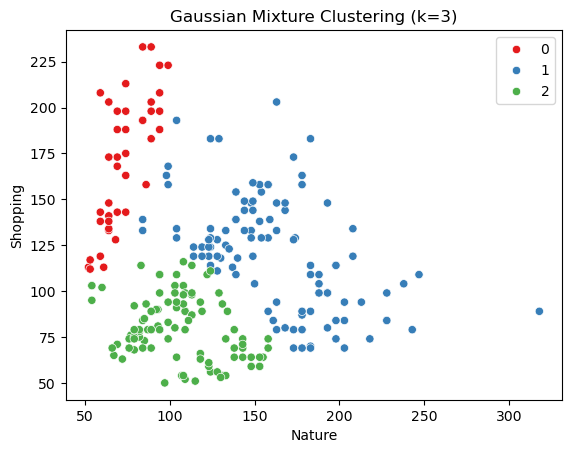

Silhouette Score for GMM with k=3: 0.3748696130750842


In [42]:
def gmm_cluster_and_score(n=3):
    X = buddydata[['Nature', 'Shopping']]
    
    # Fit GMM model
    gmm = GaussianMixture(n_components=n, random_state=0)
    gmm.fit(X)
    labels = gmm.predict(X)
    
    # Plot the clusters
    sns.scatterplot(x=X['Nature'], y=X['Shopping'], hue=labels, palette='Set1')
    plt.title(f'Gaussian Mixture Clustering (k={n})')
    plt.xlabel("Nature")
    plt.ylabel("Shopping")
    plt.show()
    
    # Calculate silhouette score
    score = silhouette_score(X, labels)
    print(f"Silhouette Score for GMM with k={n}: {score:}")

gmm_cluster_and_score(3)

Task 2.7: Use Sklearn to build a DBSCAN clustering model with parameter values eps=1 and min_samples=1, plot the corresponding scatterplot so that datapoints belonging to different clusters have different colors, and finally also print the corresponding silhouette score.

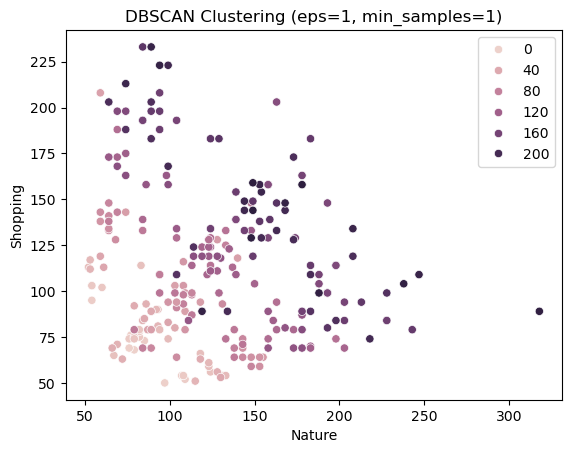

Silhouette score: 0.17406364893527249


In [44]:
X = buddydata[['Nature', 'Shopping']]

clustering = DBSCAN(eps=1, min_samples=1).fit(X)
sns.scatterplot(data=X, x="Nature", y="Shopping", hue=clustering.labels_)
plt.title("DBSCAN Clustering (eps=1, min_samples=1)")
plt.show()

score = silhouette_score(X, clustering.labels_)
print(f"Silhouette score: {score}")

Task 2.8: Try any other Sklearn clustering model (you can choose whichever you like), plot the corresponding scatterplot so that datapoints belonging to different clusters have different colors, and finally also print the corresponding silhouette score.

/opt/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


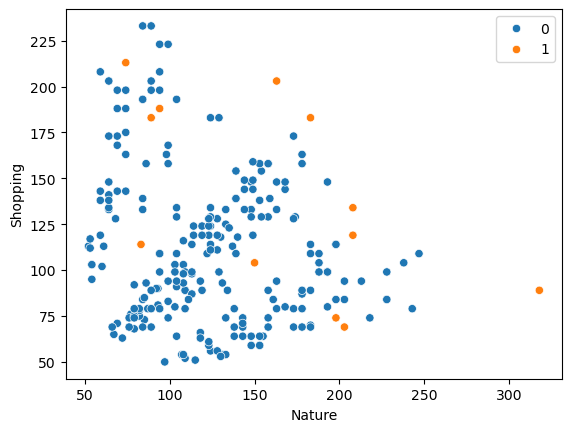

Silhouette score: 0.2521274539468432


In [46]:
clustering = SpectralClustering(n_clusters=2, assign_labels='discretize',
        random_state=0).fit(X)
clustering.labels_

sns.scatterplot(data=X, x="Nature", y="Shopping", hue=clustering.labels_)
plt.show()

s_score = silhouette_score(X, clustering.labels_)
print(f"Silhouette score: {s_score}")

Task 2.9: Which one of the four clustering models gave the best performance in terms of the silhouette score? Also explain in your own words which one you would recommend, and why?

### Task 2.9 – Comparing Clustering Models

We tested four clustering models on the `Nature` and `Shopping` features:

1. **K-Means**
2. **Gaussian Mixture**
3. **DBSCAN**
4. **Spectral Clustering**

#### Best Silhouette Score

The model with the **highest silhouette score** was:

$
\textbf{k-means clustering model}
$

This means K-Means gave the **most well-defined clusters** based on how close points were to their own group vs. other groups.

#### Recommended Model

I recommend using **K-Means**, because:

- It had the **highest silhouette score**
- It gave clear and balanced clusters
- It is simple and fast to use

While DBSCAN is good for finding odd shapes or noise, in this case, K-Means performed best.

## Task 3: PCA

Task 3.1: Here we continue with buddydata but only with the numeric columns. Save only the numeric columns of buddydata to a new variable called buddydatanum. Include all the numeric features, not just Nature and Shopping. Also print a snapshot of buddydatanum by simply writing the variable name.

In [51]:
buddydatanum = buddydata.select_dtypes(include='number')
buddydatanum.head()

,Sports,Religious,Nature,Theatre,Shopping,Picnic
0,2,77,79,69,68,95
1,2,62,76,76,69,68
2,2,50,97,87,50,75
3,2,68,77,95,76,61
4,2,98,54,59,95,86


Task 3.2: How many observations does the buddydatanum dataset contain? How many features does the buddydatanum dataset contain?

In [53]:
num_observations = buddydatanum.shape[0]
num_features = buddydatanum.shape[1]
num_observations, num_features

print(f"Number of observations: {num_observations}")
print(f"Number of features: {num_features}")

Number of observations: 249
Number of features: 6


Task 3.3: Find the correlation matrix of buddydatanum, and use Seaborn to plot a heatmap of this correlation matrix.

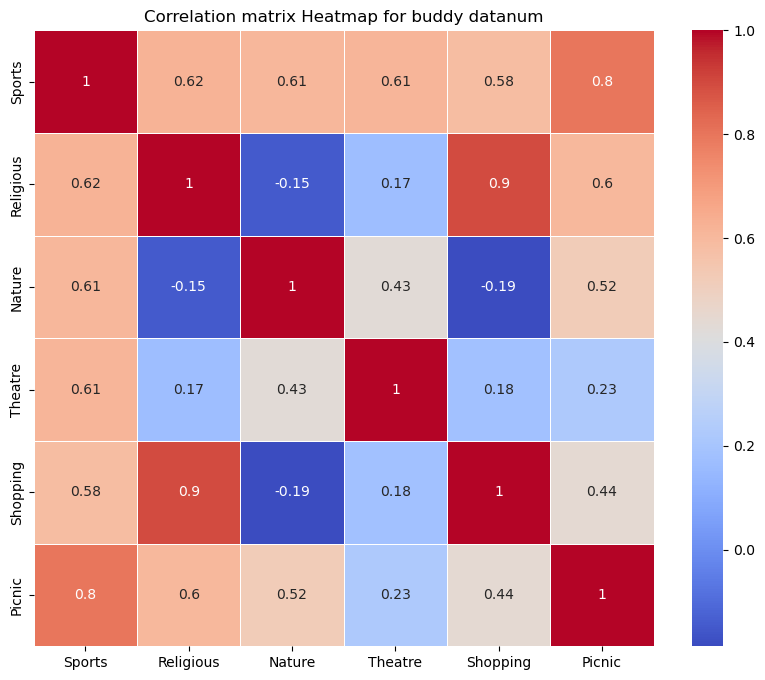

In [55]:
correlation_matrix = buddydatanum.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation matrix Heatmap for buddy datanum")
plt.show()

Task 3.4: Explain in your own words what you see in the heatmap.

The heatmap shows how strongly the activities are related to each other using **correlation** values.

- Values close to **1** (red) mean a **strong positive relationship**.
- Values close to **0** mean **no clear relationship**.
- Values below **0** (blue) mean a **negative relationship**.

#### Example observations:

- **Religious** and **Shopping**: correlation = \( 0.90 \) → strong positive relationship  
- **Sports** and **Picnic**: correlation = \( 0.80 \) → also strongly related  
- **Nature** and **Religious**: correlation = \( -0.15 \) → weak negative relationship

This means people who rate one activity highly often rate the other similarly, or differently if the value is negative.

Task 3.5: Use the Sklearn PCA algorithm with two PCA components by the PCA fit() function on buddydatanum.

In [59]:
pca = PCA(n_components=2)

pca_fit = pca.fit(buddydatanum)
pca_transformed = pca_fit.transform(buddydatanum)

print("PCA components:")
print(pca.components_)
print("\nExplained variance for each PCA component:")
print(pca.explained_variance_ratio_)

PCA components:
[[ 0.1004277   0.531791    0.14649008  0.22209214  0.66164543  0.44559363]
 [ 0.06012882 -0.19884391  0.84528475  0.28832336 -0.30582912  0.25627624]]

Explained variance for each PCA component:
[0.44690064 0.38897145]


Task 3.6: Find the explained variance ratios of the two PCA components.

- PCA Component 1: Explains 44.69% of the total variation in the dataset.
- PCA Component 2: Explains 38.90% of the total variation in the dataset.

Together, the two components explain approximately 83.59% (44.69% + 38.90%) of the total variation in the data. This means that we have managed to capture a large part of the original information with just two components.

Task 3.7: Repeat Task 3.5 and Task 3.6, but this time normalize the data using the preprocessing package. That is, first use the sklearn.preprocessing package to normalize buddydatanum, then run the Sklearn PCA algorithm with two PCA components by the PCA fit() function on the normalized version of buddydatanum.

In [63]:
scaler = StandardScaler()
buddydatanum_normalized = scaler.fit_transform(buddydatanum)

# Normalizes the data
pca_normalized = PCA(n_components=2)
pca_normalized.fit(buddydatanum_normalized)


pca_normalized_components = pca_normalized.components_
explained_variance_ratios_normalized = pca_normalized.explained_variance_ratio_

pca_normalized_components, explained_variance_ratios_normalized

(array([[ 0.53183266,  0.43430306,  0.24426526,  0.29996214,  0.4023048 ,
          0.46587866],
        [ 0.1630455 , -0.45129164,  0.64791327,  0.33808378, -0.47717358,
          0.08924771]]),
 array([0.54568291, 0.28136271]))

Task 3.8: Is there a difference in how much variance the first principle component of the "not normalized" data (of Task 3.5) explains when compared with how much variance the first principle component of the normalized data (of Task 3.7) explains? That is, are the explained variance ratios of the first principle components different without and with normalization? If so, do you believe the difference is noteworthy? Explain in your own words.


- PCA Component 1: Explains 54.57% of the total variation in the normalized data.

- PCA Component 2: Explains 28.14% of the total variation in the normalized data.

Together: These two components explain approximately 82.71% (54.57% + 28.14%) of the total variation in the normalized data.

### Task 4: kNN classification

Task 4.1: Let's now go back to beandata, and let's now say that we are interested in classifying all the beans of beandata, but we only know the AspectRation and the Area of the beans, in addition to the corresponding Class of the beans. Use Scikit-learn to build a kNN classifier with $k=3$. Train the model with a random $80\%$ selection of the whole dataset, and leave the remaining $20\%$ of the dataset as the test set.

In [68]:
print(beandata[["Area", "AspectRation", "Class"]])

X = beandata[["Area", "AspectRation"]]
y = beandata["Class"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)
score = accuracy_score(y_test, y_pred)
print(f"Accuracy: {score:}")

        Area  AspectRation     Class
0      28395      1.197191     SEKER
1      28734      1.097356     SEKER
2      29380      1.209713     SEKER
3      30008      1.153638     SEKER
4      30140      1.060798     SEKER
...      ...           ...       ...
13606  42097      1.552728  DERMASON
13607  42101      1.476439  DERMASON
13608  42139      1.472582  DERMASON
13609  42147      1.489326  DERMASON
13610  42159      1.619841  DERMASON

[13611 rows x 3 columns]
Accuracy: 0.5769372016158648


Task 4.2: Plot a Seaborn pairplot of the training set with only AspectRation and Area with hue set to Class.

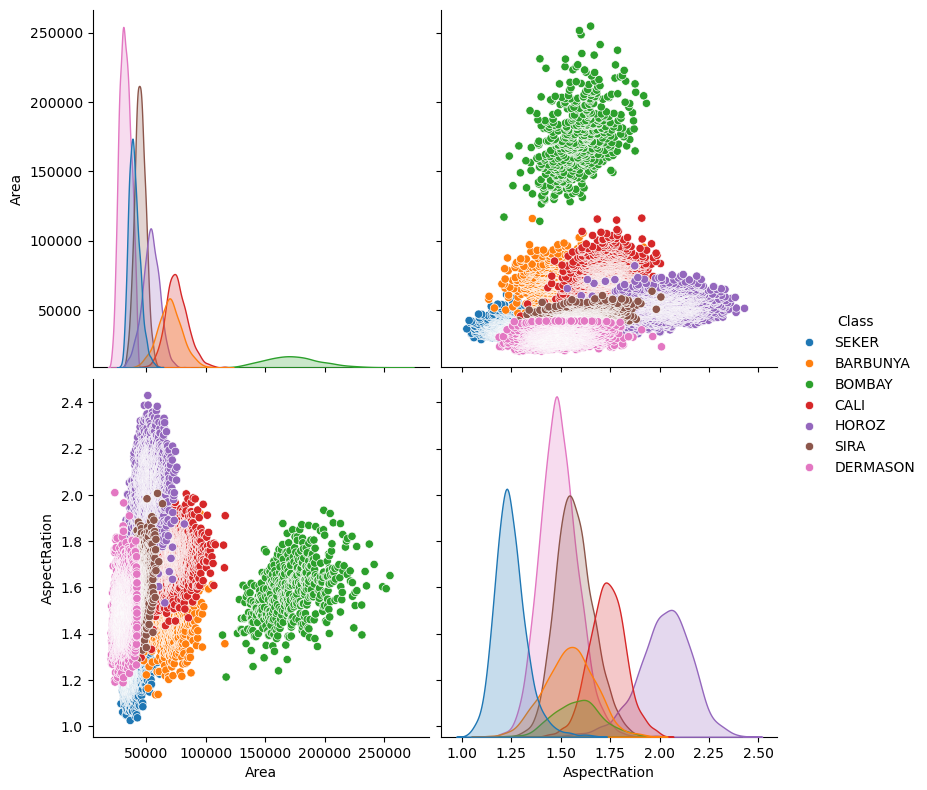

In [70]:
sns.pairplot(beandata, vars=["Area","AspectRation"], hue="Class", height=4)
plt.show()

Task 4.3: Plot a Seaborn pairplot of the test set with only AspectRation and Area with hue set to the predicted class of the kNN classifier that you just built.

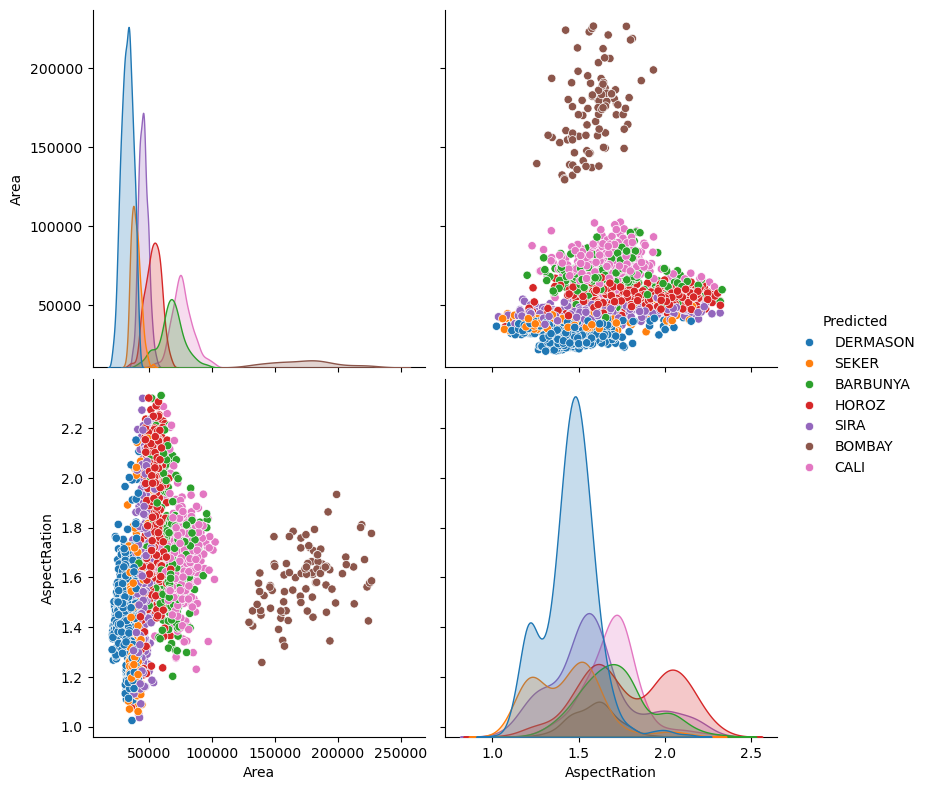

In [72]:
test_plot_data = x_test.copy()
test_plot_data["Predicted"] = y_pred

sns.pairplot(test_plot_data, vars=["Area","AspectRation"], hue="Predicted", height=4)
plt.show()

Task 4.4: Describe what you see in the pairplots above in your own words. How good are the classification results in your opinion? Here it is not a requirement to find how many beans were misclassified etc., a simple explanation is enough to pass this practice task.

The pairplot shows how the kNN model predicted the bean types using only **Area** and **AspectRation**.

- Most beans are grouped and classified well.
- The dark brown group (BOMBAY) is clearly separated, easy to classify.
- The other beans overlap more, so it's harder for the model to separate them.

Overall, the model does a pretty good job with just two features, but there is some mixing between classes.